# SolarCast NZ: when should a small workshop charge its EV?

**Veritas AI High School Hackathon 2026, AI + Climate.** [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nashwu0117/SolarCast-Lite/blob/main/notebooks/SolarCast_NZ_Judges.ipynb)

**The story.** A small workshop in New Zealand has a **50 kW rooftop solar system** and an **electric vehicle** that needs
about 40 kWh a day. Solar power changes hour by hour with the clouds. If the EV charges while the sun is strong, the
workshop uses its own clean, free power; if it charges when the sun is weak, it pulls power from the grid (it costs money
and carries CO2). So the question is: **how much solar power will we have in the next hour, and should we charge now?**

**What SolarCast NZ does.** A machine-learning model (gradient boosting, scikit-learn) forecasts the **next hour** of solar
power for 14 New Zealand regions, and the dashboard turns that forecast into simple EV charging advice.

**How to run it:** `Runtime > Run all`. It takes about 2-3 minutes. The **last cell** starts the dashboard and prints a big link.

## 1. Setup
Clone the public repository (shallow), install Flask, and use the same scikit-learn version the model was trained with.

In [ ]:
import importlib.metadata as md
import json, os, subprocess, sys

REPO = "/content/SolarCast-Lite"
# Get the code from the public GitHub repository (shallow clone: fast).
if not os.path.isdir(f"{REPO}/src"):
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/nashwu0117/SolarCast-Lite.git", REPO], check=True)

# The saved model needs the same scikit-learn version it was trained with.
want = json.load(open(f"{REPO}/models/nz_model.json"))["sklearn_version"]
need = ["flask"] + ([] if md.version("scikit-learn") == want else [f"scikit-learn=={want}"])
subprocess.run([sys.executable, "-m", "pip", "install", "-q", *need], check=True)
if "sklearn" in sys.modules and sys.modules["sklearn"].__version__ != want:
    raise SystemExit(f"scikit-learn {want} was just installed: use Runtime > Restart session, then Run all again.")

# Make `import solarcast` work.
sys.path.insert(0, f"{REPO}/src")
os.chdir(REPO)
print("ready; scikit-learn", md.version("scikit-learn"))

ready; scikit-learn 1.6.1


## 2. Load the model and the replay data
The repository ships a small replay file (the test period only), so you do **not** wait for a long weather download.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML, display
from solarcast.nz import app, config, model as nzmodel

# Load the trained model and the replay weather (about 15 months of Open-Meteo data).
svc = app.load_service()
meta = svc.meta
test = meta["metrics"]["test"]
print(f"{len(svc.regions)} regions | replay hours: {len(svc.available_times())} | "
      f"model trained on {meta['periods']['train'][0]} to {meta['periods']['train'][1]} | data: {meta['data_source']}")

14 regions | replay hours: 5309 | model trained on 2022-01-01 to 2025-01-01 | data: Open-Meteo (ERA5 reanalysis), CC BY 4.0


## 3. Model report (test period, never used for training or tuning)
- **Persistence**: "next hour = this hour". **Clear-sky persistence**: keep the current clear-sky index. Both are baselines the model must beat.
- **MAE** is the average error in kW (lower is better). **Accuracy as a share of the 50 kW system = 100 - nMAE**, with nMAE = MAE / 50 kW.

### Overall test results

In [ ]:
# Accuracy as a share of the 50 kW system: 100 - nMAE, where nMAE = MAE / 50 kW.
def accuracy(mae_kw):
    return 100 - mae_kw / config.SYSTEM_KW * 100

# Overall TEST results (daytime hours, July 2025 - Oct 2026), saved at training time.
rows = []
for key, m in test["overall"].items():
    rows.append({"model": nzmodel.MODEL_NAMES[key], "MAE (kW)": m["mae_kw"], "MAE (W/m2)": m["mae_wm2"],
                 "RMSE (kW)": m["rmse_kw"], "accuracy (% of 50 kW)": accuracy(m["mae_kw"]), "hours": m["n"]})
overall = pd.DataFrame(rows).round(2)
display(overall)
best, pers = test["overall"]["model"]["mae_kw"], test["overall"]["persistence"]["mae_kw"]
print(f"The model's error is {100 - best / pers * 100:.0f} % lower than persistence.")

,model,MAE (kW),MAE (W/m2),RMSE (kW),accuracy (% of 50 kW),hours
0,SolarCast model,1.19,31.29,1.98,97.62,73746
1,Persistence,4.03,105.44,4.80,91.93,73746
2,Clear-sky persistence,1.66,43.82,2.69,96.68,73746


The model's error is 71 % lower than persistence.


### Per region

In [ ]:
# Per-region TEST MAE in kW (lower is better).
rows = []
for region, d in test["per_region"].items():
    rows.append({"region": region, "model": d["model"]["mae_kw"], "persistence": d["persistence"]["mae_kw"],
                 "clear-sky persistence": d["clear_sky"]["mae_kw"], "model accuracy (%)": accuracy(d["model"]["mae_kw"])})
display(pd.DataFrame(rows).round(2).set_index("region"))

,model,persistence,clear-sky persistence,model accuracy (%)
region,,,,
Auckland,1.16,4.28,1.67,97.67
Christchurch,1.02,3.94,1.47,97.95
Dunedin,1.22,3.64,1.62,97.56
Gisborne,1.15,4.17,1.63,97.70
Hamilton,1.26,4.13,1.67,97.48
Invercargill,1.35,3.72,1.87,97.30
Napier,1.11,4.15,1.67,97.78
Nelson,1.12,3.98,1.42,97.76
New Plymouth,1.09,4.09,1.58,97.83


### Learning curve
More training days means a lower error, and the gain flattens after about a year of data.

In [ ]:
# Learning curve: how the error falls as the model sees more training days.
curve = pd.DataFrame(meta["learning_curve"])
curve["accuracy (% of 50 kW)"] = accuracy(curve["model_mae_kw"])
display(curve[["days", "train_rows", "model_mae_wm2", "model_mae_kw", "accuracy (% of 50 kW)",
               "persistence_mae_wm2", "clear_sky_mae_wm2"]].round(2).set_index("days"))

,train_rows,model_mae_wm2,model_mae_kw,accuracy (% of 50 kW),persistence_mae_wm2,clear_sky_mae_wm2
days,,,,,,
7,2352,48.54,1.82,96.36,104.67,41.48
30,10080,44.60,1.68,96.63,104.67,41.48
90,30240,37.29,1.41,97.18,104.67,41.48
180,60480,31.85,1.19,97.61,104.67,41.48
365,122640,30.88,1.16,97.69,104.67,41.48
730,245280,30.52,1.14,97.71,104.67,41.48
all (~1096),368242,30.35,1.14,97.73,104.67,41.48


### One sample week

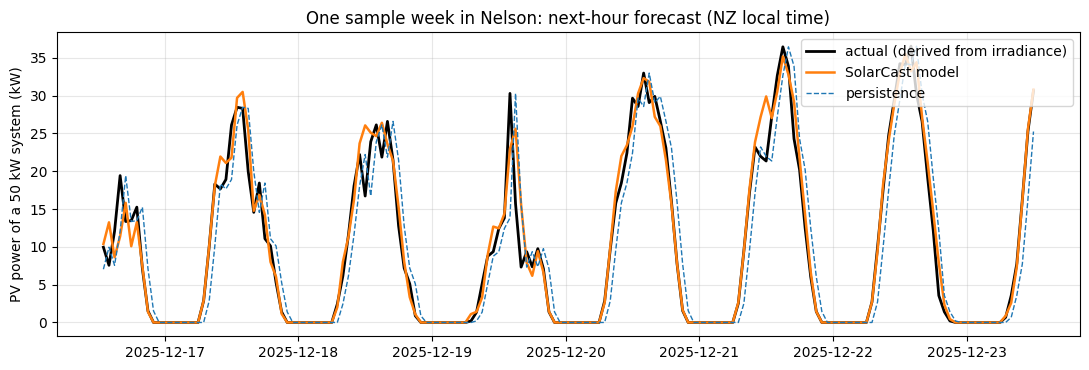

In [ ]:
# One sample week: actual power vs. the model vs. the persistence baseline.
s = meta["report"]["sample"]
t = pd.to_datetime(s["times"]).tz_convert(config.LOCAL_TZ)
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(t, s["actual_kw"], color="black", lw=2, label="actual (derived from irradiance)")
ax.plot(t, s["predicted_kw"], color="tab:orange", lw=1.8, label="SolarCast model")
ax.plot(t, s["persistence_kw"], color="tab:blue", lw=1, ls="--", label="persistence")
ax.set_ylabel("PV power of a 50 kW system (kW)")
ax.set_title(f"One sample week in {s['region']}: next-hour forecast (NZ local time)")
ax.legend(loc="upper right")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Honest notes
- The weather is **Open-Meteo modelled data (ERA5-based reanalysis)**, not measurements from real solar plants.
- The PV power is **derived from irradiance** with a stated formula (50 kW x GHI/1000 x 0.80 performance ratio, with a small temperature loss). New Zealand has no public per-site hourly PV output data.
- A real plant would be harder: shading, dirt, inverter limits, outages and forecast errors all add noise.
- This is a **prototype**. It is **not energy or financial advice**.

## Credits
Weather data: [Open-Meteo](https://open-meteo.com) (CC BY 4.0) | Machine learning: scikit-learn | Web server: Flask |
Map: Leaflet with OpenStreetMap | Charts: Chart.js | Public link: Cloudflare cloudflared |
AI tool: Claude Code (Anthropic) helped write and test the code.

## 5. FINAL STEP: start the dashboard
Run the cell below. It prints a **big link** to the SolarCast NZ dashboard (map of New Zealand: hover a region for weather and
generation, click it for the day chart, EV advice and savings; the Model tab shows the report above; use the Replay slider
or the Live button). Keep this notebook running while you use the link.

In [ ]:
# Start the dashboard (Flask) and open a free Cloudflare tunnel so anyone can reach it.
from solarcast.nz import webapp
url = webapp.serve(svc, port=8000, tunnel=True)

# Show the link big. If there is no tunnel, the local URL is shown instead.
display(HTML(f"""
<div style="padding:28px;margin:16px 0;border:4px solid #f59e0b;border-radius:16px;background:#fffbeb;text-align:center">
  <a href="{url}" target="_blank" style="font-size:36px;font-weight:700;color:#b45309">Open the SolarCast NZ dashboard</a>
  <div style="font-size:16px;margin-top:10px;color:#444">{url}</div>
</div>"""))
print(url)